# 📚 Book Ratings Insights

What makes a book loved by readers? This notebook explores the
[goodbooks-10k](https://github.com/zygmuntz/goodbooks-10k) dataset, with 10,000
popular books from Goodreads and about 6 million ratings given by their readers.

All the logic lives in the `bookinsights` package: this notebook only calls its
functions and shows the results.

1. **Setup**: import the package
2. **The data**: download and load the files
3. **Cleaning**: genres, publication eras, authors and series

### Research questions

**Books**
1. Are some genres consistently rated higher than others?
2. Are older books rated differently than recent ones?
3. Is popularity the same as appreciation? Do the most read books get higher ratings?

**Authors and series**

4. How do the ratings of an author evolve across their works?
5. What happens as a series goes on? Are later books rated higher or lower than the first one?

**Readers**

6. How do readers rate? Are users who rate many books harsher, or more consistent, than occasional readers?

## 1. Setup

The notebook lives in the `notebooks/` folder, while the `bookinsights` package is
one level up, in the project folder. Python only looks for packages in a few places,
so we add the project folder to that list (`sys.path`).

The `autoreload` extension reloads the modules of the package whenever they change,
without restarting the kernel.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys

# Jupyter runs the notebook from the folder that contains it (notebooks/),
# so the project folder is its parent
PROJECT_ROOT = os.path.dirname(os.getcwd())

# Let Python find the bookinsights package, which lives in the project folder
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

In [3]:
from bookinsights.analysis import (
    compare_series_to_first,
    correlate_with_rating,
    genre_shares,
    last_main_books,
    summarize_by_group,
    summarize_by_popularity,
    summarize_series_kinds,
    summarize_series_progression,
    test_difference_from_first,
    test_group_differences,
)
from bookinsights.cleaning import clean_books
from bookinsights.data import (
    download_data,
    load_book_tags,
    load_books,
    load_ratings,
    load_tags,
)
from bookinsights.plots import (
    plot_popularity_vs_rating,
    plot_rating_distribution,
    plot_ratings_by_group,
    plot_series_progression,
)

## 2. The data

The data files are not stored in the repository, since they are too large for
GitHub. `download_data()` downloads them into the `data/` folder the first time,
and does nothing when they are already there.

In [4]:
paths = download_data()

# relpath shows the paths starting from the project folder, which is shorter to read
{name: os.path.relpath(path, PROJECT_ROOT) for name, path in paths.items()}

{'books.csv': 'data/books.csv',
 'ratings.csv': 'data/ratings.csv',
 'tags.csv': 'data/tags.csv',
 'book_tags.csv': 'data/book_tags.csv'}

The dataset is made of four tables:

- `books`: the metadata of each book (authors, title, year, ratings);
- `ratings`: one row for each rating, from 1 to 5, given by a user to a book;
- `tags`: the names of the tags, i.e. the shelves where users put the books;
- `book_tags`: how many users put each book on each shelf.

Ratings are linked to books through `book_id`, while tags are linked through
`goodreads_book_id`.

In [5]:
books = load_books()
ratings = load_ratings()
tags = load_tags()
book_tags = load_book_tags()

for name, table in [
    ("books", books),
    ("ratings", ratings),
    ("tags", tags),
    ("book_tags", book_tags),
]:
    print(f"{name:<10} {table.shape[0]:>9,} rows  {table.shape[1]:>2} columns")

books         10,000 rows  15 columns
ratings    5,976,479 rows   3 columns
tags          34,252 rows   2 columns
book_tags    999,912 rows   3 columns


In [6]:
books.head()

,book_id,goodreads_book_id,authors,original_publication_year,title,language_code,average_rating,ratings_count,work_ratings_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url
0,1,2767052,Suzanne Collins,2008.0,"The Hunger Games (The Hunger Games, #1)",eng,4.34,4780653,4942365,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...
1,2,3,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Sorcerer's Stone (Harry P...,eng,4.44,4602479,4800065,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...
2,3,41865,Stephenie Meyer,2005.0,"Twilight (Twilight, #1)",en-US,3.57,3866839,3916824,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...
3,4,2657,Harper Lee,1960.0,To Kill a Mockingbird,eng,4.25,3198671,3340896,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...
4,5,4671,F. Scott Fitzgerald,1925.0,The Great Gatsby,eng,3.89,2683664,2773745,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...


`ratings` is the largest table, with about 6 million rows. Its values are small
integers (user ids up to 53,424, book ids up to 10,000 and ratings from 1 to 5), so
`load_ratings` stores them with compact types instead of the default `int64`.

In [7]:
print(ratings.dtypes)
print(f"Memory: {ratings.memory_usage(deep=True).sum() / 1e6:.1f} MB")

user_id    int32
book_id    int16
rating      int8
dtype: object
Memory: 41.8 MB


### How are the books rated?

`average_rating` is the mean of all the ratings that Goodreads users gave to a book,
from 1 to 5 stars. It is the main variable of the analysis.

In [8]:
books["average_rating"].agg(["mean", "median", "std", "skew"])

mean      4.002191
median    4.020000
std       0.254427
skew     -0.511617
Name: average_rating, dtype: float64

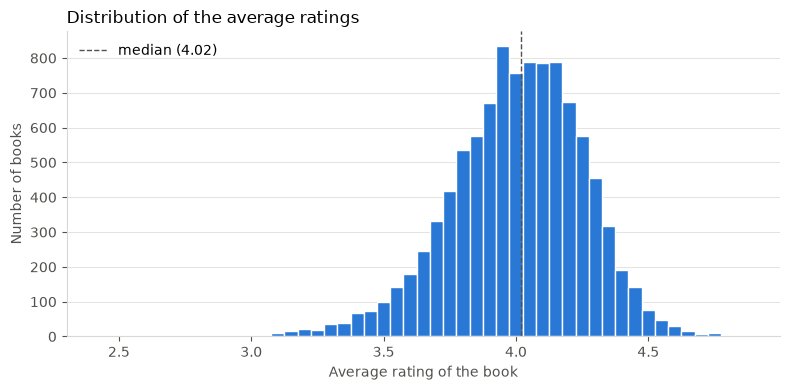

In [9]:
fig = plot_rating_distribution(books)

The ratings are concentrated in a narrow range: 95% of the books have an average
between 3.5 and 4.5 stars, and the standard deviation is only 0.25. A difference of
0.1 stars between two groups of books is therefore not negligible.

The distribution is not symmetric: it has a longer tail on the left (skewness
$-0.51$), made of the few books that readers did not like. This is why, in the
following sections, we compare groups with tests that do not assume normal data.

## 3. Cleaning

`clean_books` builds the table used in the analysis. The main choices are:

- **Genres.** Tags are user shelves, and most of them are not genres (`to-read`,
  `favorites`, `owned`, ...). We keep a list of 18 genres, merging synonyms
  (e.g. `sci-fi` and `science-fiction`), and give each book its **primary genre**:
  the genre tag used by the largest number of users. `young-adult` and `children`
  describe an audience, but they are kept, since Goodreads uses them as genres.
  Rows with a negative count (6) and duplicated rows (8) are removed from the tags.
- **Publication eras.** Years are grouped into six eras; ancient books (with
  negative years, e.g. *The Epic of Gilgamesh*) fall into "before 1800".
- **Main author.** When a book lists several names, the first one is the author:
  the others are usually illustrators, translators or narrators.
- **Series.** The series and the position in it are extracted from the title, e.g.
  *(The Hunger Games, #1)*. Box sets (e.g. *#1-7*) are not single books, so they
  are not assigned to a series.

In [10]:
clean = clean_books(books, book_tags, tags)
clean[
    [
        "title",
        "main_author",
        "publication_year",
        "era",
        "series",
        "series_number",
        "genre",
    ]
].head(10)

,title,main_author,publication_year,era,series,series_number,genre
0,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,2008,2000-2009,The Hunger Games,1.0,young-adult
1,Harry Potter and the Sorcerer's Stone (Harry P...,J.K. Rowling,1997,1950-1999,Harry Potter,1.0,fantasy
2,"Twilight (Twilight, #1)",Stephenie Meyer,2005,2000-2009,Twilight,1.0,young-adult
3,To Kill a Mockingbird,Harper Lee,1960,1950-1999,NaN,NaN,classics
4,The Great Gatsby,F. Scott Fitzgerald,1925,1900-1949,NaN,NaN,classics
5,The Fault in Our Stars,John Green,2012,2010 or later,NaN,NaN,young-adult
6,The Hobbit,J.R.R. Tolkien,1937,1900-1949,NaN,NaN,fantasy
7,The Catcher in the Rye,J.D. Salinger,1951,1950-1999,NaN,NaN,classics
8,"Angels & Demons (Robert Langdon, #1)",Dan Brown,2000,2000-2009,Robert Langdon,1.0,mystery
9,Pride and Prejudice,Jane Austen,1813,1800-1899,NaN,NaN,classics


How many books fall into each genre? A few books (cookbooks, religious books, ...)
have no tag of the list, so they have no genre.

In [11]:
clean["genre"].value_counts(dropna=False)

genre
fantasy               1230
young-adult           1116
romance               1086
mystery               1060
historical-fiction     796
classics               767
biography              584
children               555
science-fiction        476
comics                 394
thriller               306
self-help              298
history                288
horror                 260
humor                  231
philosophy             222
literary-fiction       222
poetry                  64
NaN                     45
Name: count, dtype: int64

Most books were published after 1950: older books are only the ones that are still
read today.

In [12]:
clean["era"].value_counts(sort=False, dropna=False)

era
before 1800       125
1800-1899         254
1900-1949         466
1950-1999        2946
2000-2009        3121
2010 or later    3067
NaN                21
Name: count, dtype: int64

The series with the largest number of books in the dataset:

In [13]:
clean["series"].value_counts().head(10)

series
In Death                       41
Discworld                      39
Stephanie Plum                 27
Hercule Poirot                 25
Kinsey Millhone                24
Alex Cross                     23
Jack Reacher                   23
Kay Scarpetta                  23
Anita Blake, Vampire Hunter    23
Harry Bosch                    21
Name: count, dtype: int64

## 4. Are some genres consistently rated higher than others?

Each book is one observation, described by its `average_rating`: this way every book
counts the same, whatever its number of ratings. The 45 books without a genre are left
out.

In [14]:
summarize_by_group(clean, "genre").round(3)

,n_books,mean,median,std,weighted_mean
genre,,,,,
comics,394,4.224,4.230,0.213,4.246
poetry,64,4.166,4.215,0.232,4.200
children,555,4.140,4.160,0.175,4.174
fantasy,1230,4.098,4.115,0.239,4.197
romance,1086,4.012,4.060,0.279,4.004
history,288,4.040,4.055,0.220,4.042
philosophy,222,4.003,4.030,0.225,3.992
self-help,298,4.026,4.025,0.194,3.991
biography,584,3.985,4.000,0.232,3.977


Comics, poetry and children's books are at the top, literary fiction, humor and
horror at the bottom. The gap between the first and the last genre is about 0.5
stars: it looks small, but the standard deviation of all the books is only 0.25.

The `weighted_mean` column counts each book as many times as its ratings, i.e. it is
the average of the single ratings. The ranking is similar: the main exceptions are
fantasy and historical fiction, which go up, since their most popular books (e.g.
*Harry Potter*, *The Help*) are also very well rated.

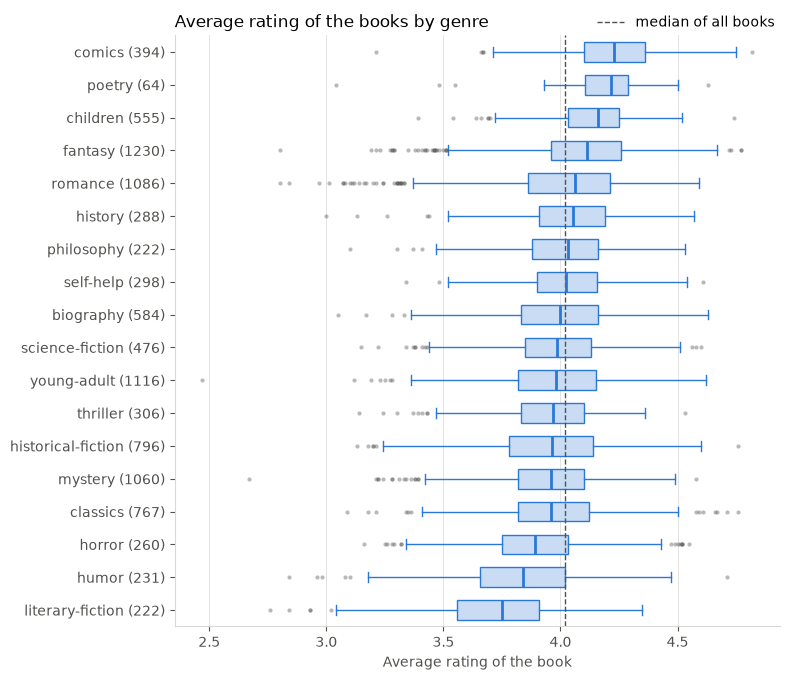

In [15]:
fig = plot_ratings_by_group(clean, "genre")

The boxes show that the differences are not only in the averages: the whole
distribution of comics and children's books is shifted to the right, and the boxes of
the first and the last genres barely overlap. Each genre still has a wide spread,
though: a good literary novel is rated higher than an average comic.

### Is the difference significant?

To compare 18 groups we could use the one-way ANOVA, but it assumes normal groups with
equal variances, and neither holds here: the ratings are skewed to the left and the
spread changes from genre to genre (e.g. the standard deviation goes from 0.18 for
children's books to 0.30 for humor). We use the **Kruskal-Wallis** test instead,
which compares the ranks of the ratings and makes no assumption on their distribution.

- $H_0$: the ratings of all the genres come from the same distribution;
- $H_1$: at least one genre tends to be rated differently.

With almost 10,000 books even a tiny difference would be significant, so we also
compute an effect size, the **epsilon squared**
$\varepsilon^2 = \frac{H - k + 1}{n - k}$, where $k$ is the number of genres and $n$
the number of books.

In [16]:
test_group_differences(clean, "genre")

{'statistic': 1261.5216864803256,
 'p_value': 8.337277685931834e-258,
 'epsilon_squared': 0.12524118813327217,
 'n_books': 9955,
 'n_groups': 18}

The p-value is practically zero, so we reject $H_0$: the genres are not rated
the same. The effect size $\varepsilon^2 \approx 0.13$ means that the genre explains
about 13% of the variability of the ranks, a **moderate** effect.

**Answer.** Yes: some genres are consistently rated higher. Comics, poetry, children's
books and fantasy are rated above the other genres, literary fiction, humor and horror
below. Still, the genre explains only a part of the rating: most of the differences
are between the books of the same genre.

## 5. Are older books rated differently than recent ones?

We look at the publication year in two ways: grouped into eras, to compare the
distributions as we did for the genres, and as a number, to look for a trend. The 21
books without a publication year are left out.

In [17]:
summarize_by_group(clean, "era", sort_by_median=False).round(3)

,n_books,mean,median,std,weighted_mean
era,,,,,
before 1800,125,3.906,3.88,0.241,3.847
1800-1899,254,3.958,3.97,0.213,3.965
1900-1949,466,4.033,4.06,0.216,4.037
1950-1999,2946,4.034,4.05,0.221,4.073
2000-2009,3121,3.977,3.99,0.265,4.011
2010 or later,3067,3.999,4.02,0.277,4.042


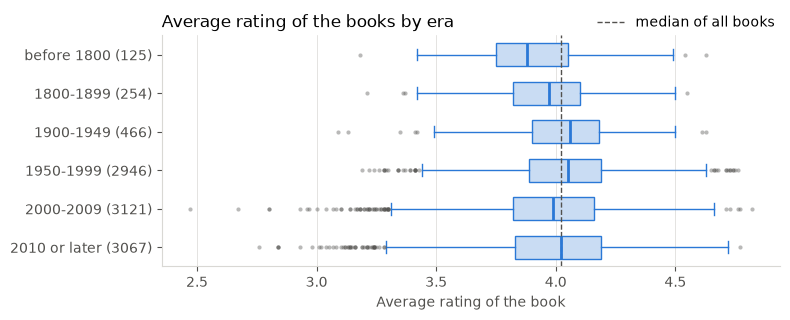

In [18]:
fig = plot_ratings_by_group(clean, "era", sort_by_median=False)

In [19]:
test_group_differences(clean, "era")

{'statistic': 106.87627864463084,
 'p_value': 1.872338225032078e-21,
 'epsilon_squared': 0.010215208928570224,
 'n_books': 9979,
 'n_groups': 6}

The differences between the eras are statistically significant, but very small:
$\varepsilon^2 \approx 0.01$, i.e. the era explains about 1% of the variability of
the ranks, ten times less than the genre. The pattern is not a trend either: the books
of the 20th century are the best rated, those before 1800 the worst, and recent books
are in between.

The **Spearman correlation** between the publication year and the rating confirms that
there is no trend. Like the Kruskal-Wallis test, it works on ranks, so it does not
assume a linear relation and it is not affected by the very old books (down to 1750
BC).

In [20]:
correlate_with_rating(clean, "publication_year")

{'rho': -0.027013626482248032,
 'p_value': 0.006961526322057463,
 'n_books': 9979}

$\rho \approx -0.03$: practically no relation, even though the p-value is
below 0.05. Again, with 10,000 books a p-value alone says little.

### A selection effect

The dataset contains the 10,000 most popular books on Goodreads, so the old books in it
are not a random sample of old books: they are the ones still read today, mostly
classics. The share of each genre in each era shows it:

In [21]:
genre_shares(clean, "era")[["classics", "fantasy", "young-adult", "romance"]].round(2)

genre,classics,fantasy,young-adult,romance
era,,,,
before 1800,0.58,0.01,0.00,0.00
1800-1899,0.78,0.00,0.00,0.01
1900-1949,0.47,0.01,0.01,0.00
1950-1999,0.09,0.12,0.04,0.05
2000-2009,0.00,0.15,0.13,0.11
2010 or later,0.00,0.12,0.20,0.19


Most books published before 1950 are classics, a genre rated below average
(often read for school rather than by choice), while there are no classics among the
recent books. If we leave the classics out, the oldest books are no longer the worst
rated:

In [22]:
not_classics = clean[clean["genre"] != "classics"]
summarize_by_group(not_classics, "era", sort_by_median=False)[["n_books", "median"]]

,n_books,median
era,,
before 1800,52,3.970
1800-1899,56,4.075
1900-1949,247,4.090
1950-1999,2683,4.050
2000-2009,3109,3.990
2010 or later,3066,4.020


**Answer.** Not really. The era explains only about 1% of the differences in
rating, and there is no trend over the years. The slightly lower ratings of the oldest
books depend on their genre: they are mostly classics, and without the classics they
are rated like the others.

## 6. Is popularity the same as appreciation?

We measure the popularity of a book by `work_ratings_count`, the number of ratings
received by all its editions. It is extremely skewed: the median book has about 24,000
ratings, the most rated one almost 5 million. This is why we use the Spearman
correlation, which works on ranks, and a logarithmic axis in the chart.

In [23]:
correlate_with_rating(clean, "work_ratings_count")

{'rho': 0.06522809347356445,
 'p_value': 6.623353542909254e-11,
 'n_books': 10000}

$\rho \approx 0.07$: the most rated books are not rated noticeably higher. To see
the whole picture, we split the books into ten groups of the same size by number of
ratings, from the 10% least rated books (group 1) to the 10% most rated ones
(group 10).

In [24]:
summarize_by_popularity(clean).round(3)

,n_books,min_ratings_count,median_ratings_count,median,min,std
popularity_group,,,,,,
1,1000,5510,10880.0,4.000,2.76,0.288
2,1000,12063,13180.5,3.990,2.80,0.266
3,1001,14228,15439.0,3.990,3.02,0.255
4,999,16707,18112.0,4.030,2.93,0.252
5,1000,19744,21565.5,4.010,2.80,0.257
6,1000,23834,26266.5,4.040,2.84,0.242
7,1000,29331,33440.0,4.040,2.67,0.242
8,1000,38782,45916.0,4.025,2.47,0.255
9,1000,55675,72524.0,4.040,3.07,0.243


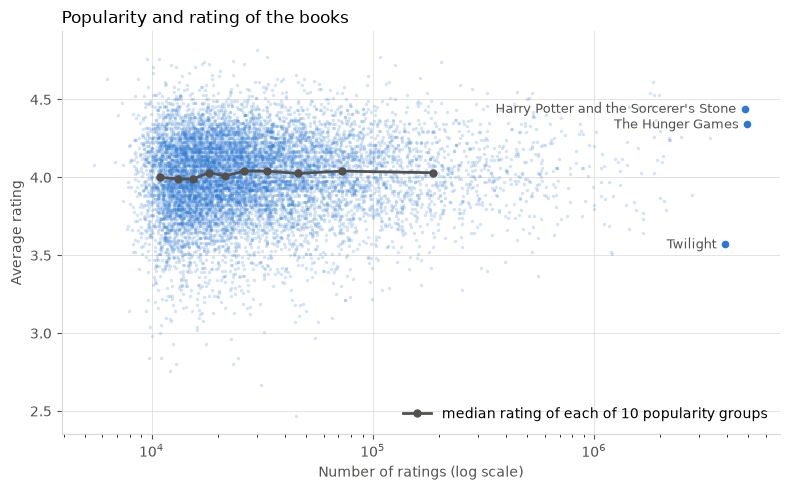

In [25]:
fig = plot_popularity_vs_rating(clean)

The line of the medians is almost flat: from 4.00 in the least popular group to
4.03 in the most popular one. Popularity, however, changes the spread: the most
popular books are never rated really badly (the lowest rating in group 10 is 3.28,
against 2.5-3.1 in the other groups), probably because a book that readers dislike stops
being recommended and read. Still, being read by millions does not guarantee a high
rating: *Twilight* is among the three most rated books, with an average of only
3.57.

Note that all the books in the dataset are popular (at least 5,500 ratings), so we are
comparing popular and very popular books: books that almost nobody read are not
here.

**Answer.** No: popularity and appreciation are different things. The number of
ratings is almost unrelated to the average rating; the most popular books only avoid
the lowest ratings.

## 7. What happens as a series goes on?

We compare each book of a series with the **first book of the same series**: the
difference in rating, and the number of ratings as a share of those of the first book.
Comparing books of the same series removes the differences between series (some series
are simply better than others).

- A series is identified by its name *and* its author, since different authors use the
  same series name (e.g. there are two series called *The Secret*).
- We keep the series whose first book is in the data and with at least three main
  books.
- Novellas and prequels (e.g. *#1.5* or *#0*) are kept apart: they are a different kind
  of book, and we look at them at the end of the section.

For example, the *Harry Potter* series:

In [26]:
series = compare_series_to_first(clean)
series.loc[
    series["series"] == "Harry Potter",
    ["title", "series_number", "average_rating", "rating_diff", "ratings_ratio"],
].round(2)

,title,series_number,average_rating,rating_diff,ratings_ratio
1,Harry Potter and the Sorcerer's Stone (Harry P...,1.0,4.44,0.00,1.00
22,Harry Potter and the Chamber of Secrets (Harry...,2.0,4.37,-0.07,0.40
17,Harry Potter and the Prisoner of Azkaban (Harr...,3.0,4.53,0.09,0.41
23,Harry Potter and the Goblet of Fire (Harry Pot...,4.0,4.53,0.09,0.39
20,Harry Potter and the Order of the Phoenix (Har...,5.0,4.46,0.02,0.38
26,Harry Potter and the Half-Blood Prince (Harry ...,6.0,4.54,0.10,0.37
24,Harry Potter and the Deathly Hallows (Harry Po...,7.0,4.61,0.17,0.38


The last book is rated 0.17 stars higher than the first one, but it received only
38% of its ratings. Is this true for the series in general?

In [27]:
progression = summarize_series_progression(series)
progression.round(3)

,n_series,median_rating_diff,share_higher,median_ratings_ratio
position,,,,
1,538,0.000,0.000,1.000
2,525,0.090,0.724,0.574
3,522,0.100,0.741,0.476
4,279,0.120,0.742,0.407
5,184,0.130,0.788,0.365
6,140,0.135,0.779,0.353
7,98,0.120,0.755,0.326
8,74,0.100,0.703,0.289
9,60,0.150,0.783,0.313


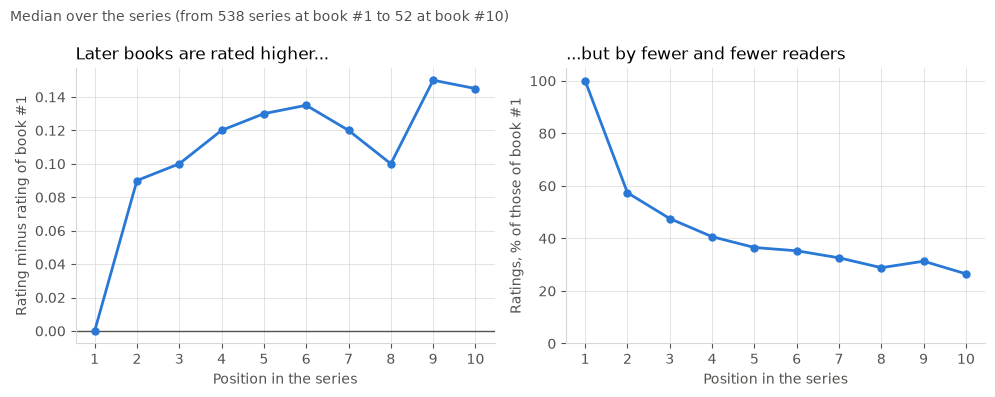

In [28]:
fig = plot_series_progression(progression)

Two opposite trends appear:

- **The ratings go up.** Already the second book is rated 0.09 stars higher than the
  first one (median), and about three books out of four are rated higher than the first
  book of their series.
- **The readers go down.** The second book receives about half the ratings of the first
  one, the tenth about a quarter.

The two trends are probably two sides of the same phenomenon, **self-selection**:
readers who did not like the first book do not read the following ones. The later books
are rated only by the fans of the series, who rate them generously. So the higher
ratings do not necessarily mean that the later books are better.

### Is the difference significant?

For each series, we compare its last main book with its first book. The data are
**paired** (each book is compared with the first book of its own series), so we use the
**Wilcoxon signed-rank test**, which tests whether the differences are centered on zero
without assuming that they are normal.

- $H_0$: the last book is rated like the first one (median difference 0);
- $H_1$: it is rated differently.

In [29]:
test_difference_from_first(last_main_books(series)["rating_diff"])

{'n_books': 538,
 'median_diff': 0.1200000000000001,
 'share_higher': 0.7304832713754646,
 'statistic': 29885.5,
 'p_value': 6.590581965949831e-31}

The last book is rated 0.12 stars higher than the first one (median) and the
p-value is practically zero: the increase is systematic.

### Novellas and prequels

Novellas and prequels are often loved by the readers of a series. How do they compare
with the first book?

In [30]:
summarize_series_kinds(series).round(3)

,n_books,n_series,median_rating_diff,share_higher,median_ratings_ratio
kind,,,,,
main,2232,538,0.10,0.728,0.416
in-between,70,43,-0.05,0.429,0.093


In [31]:
in_between = series[series["kind"] == "in-between"]
test_difference_from_first(in_between["rating_diff"])

{'n_books': 70,
 'median_diff': -0.04999999999999982,
 'share_higher': 0.42857142857142855,
 'statistic': 913.5,
 'p_value': 0.1127973831747793}

In [32]:
in_between.nlargest(5, "work_ratings_count")[
    ["title", "average_rating", "rating_diff", "ratings_ratio"]
].round(2)

,title,average_rating,rating_diff,ratings_ratio
431,"I, Robot (Robot #0.1)",4.17,0.03,3.62
731,The Short Second Life of Bree Tanner: An Eclip...,3.51,-0.06,0.04
833,"Midnight Sun (Twilight, #1.5)",4.03,0.46,0.04
945,"The Kill Order (Maze Runner, #0.5)",3.69,-0.33,0.14
1196,Free Four: Tobias Tells the Divergent Knife-Th...,4.18,-0.06,0.04


Novellas and prequels are read by an even smaller group: they receive only about
9% of the ratings of the first book, so only the most devoted fans rate them. If
self-selection were the whole story, they should be the best rated books of the series.
They are not: their median rating is slightly *lower* than that of the first book, and
only 43% of them are rated higher (the difference is not significant, p ≈ 0.11). Fans
seem to appreciate them as extras, but not as much as the main novels.

**Answer.** As a series goes on, its books are rated higher but by fewer readers: the
last book is rated about 0.12 stars higher than the first one, with a fraction of its
readers. This is mostly self-selection: only the readers who liked the beginning keep
reading. Novellas and prequels, read only by the most devoted fans, do not follow this
pattern.